In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/creditcard.csv")
print(df.shape)
print(df["Class"].value_counts())
print(f"Fraud rate: {df['Class'].mean()*100:.3f}%")
df.head()

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64
Fraud rate: 0.173%


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


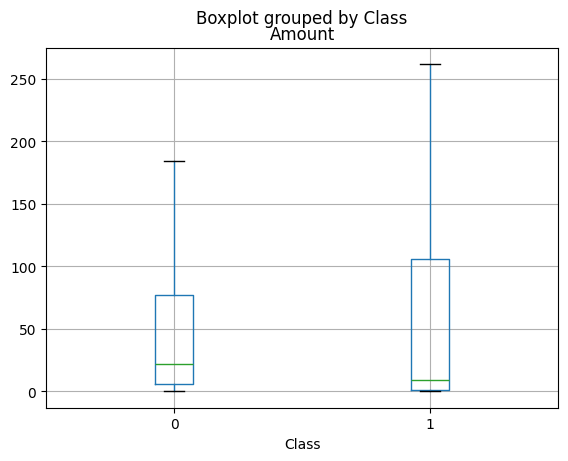

In [2]:
import matplotlib.pyplot as plt

print(df.groupby("Class")["Amount"].describe())
df.boxplot(column="Amount", by="Class", showfliers=False)
plt.show()

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


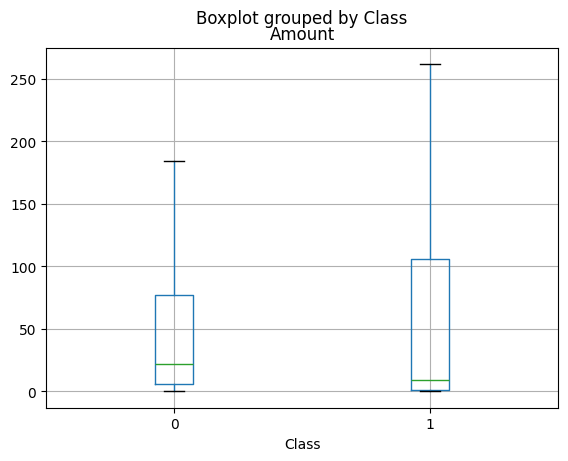

In [3]:
import matplotlib.pyplot as plt

print(df.groupby("Class")["Amount"].describe())
df.boxplot(column="Amount", by="Class", showfliers=False)
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train = X_train.copy()
X_test = X_test.copy()

scaler = RobustScaler()
X_train[["Amount", "Time"]] = scaler.fit_transform(X_train[["Amount", "Time"]])
X_test[["Amount", "Time"]] = scaler.transform(X_test[["Amount", "Time"]])

print(X_train.shape, X_test.shape)
print("Fraud in train:", y_train.sum(), "| Fraud in test:", y_test.sum())

(227845, 30) (56962, 30)
Fraud in train: 394 | Fraud in test: 98


In [5]:
import numpy as np
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix)

results = []

def evaluate(name, y_true, y_pred, y_score=None):
    row = {
        "Model": name,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "PR-AUC": average_precision_score(y_true, y_score) if y_score is not None else np.nan,
    }
    results.append(row)
    print(name)
    print(confusion_matrix(y_true, y_pred), "\n")

In [6]:
raw_amount_test = df.loc[X_test.index, "Amount"]
threshold = df.loc[X_train.index, "Amount"].quantile(0.99)
print("Rule threshold:", round(threshold, 2))

rule_pred = (raw_amount_test > threshold).astype(int)
evaluate("Rule-based (amount > 99th percentile)", y_test, rule_pred)

Rule threshold: 1012.34
Rule-based (amount > 99th percentile)
[[56265   599]
 [   97     1]] 



In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

lr = LogisticRegression(max_iter=1000, class_weight="balanced")
lr.fit(X_train, y_train)
evaluate("Logistic Regression", y_test, lr.predict(X_test), lr.predict_proba(X_test)[:, 1])

rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
evaluate("Random Forest", y_test, rf.predict(X_test), rf.predict_proba(X_test)[:, 1])

ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                    scale_pos_weight=ratio, eval_metric="aucpr",
                    n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train)
evaluate("XGBoost", y_test, xgb.predict(X_test), xgb.predict_proba(X_test)[:, 1])

Logistic Regression
[[55476  1388]
 [    8    90]] 

Random Forest
[[56861     3]
 [   26    72]] 

XGBoost
[[56852    12]
 [   15    83]] 



In [8]:
pd.DataFrame(results).round(3)

,Model,Precision,Recall,F1,PR-AUC
0,Rule-based (amount > 99th percentile),0.002,0.010,0.003,NaN
1,Logistic Regression,0.061,0.918,0.114,0.717
2,Random Forest,0.960,0.735,0.832,0.860
3,XGBoost,0.874,0.847,0.860,0.876


In [9]:
import joblib

joblib.dump(xgb, "../models/xgb_transaction.joblib")
joblib.dump(scaler, "../models/scaler.joblib")
print("Saved")

Saved


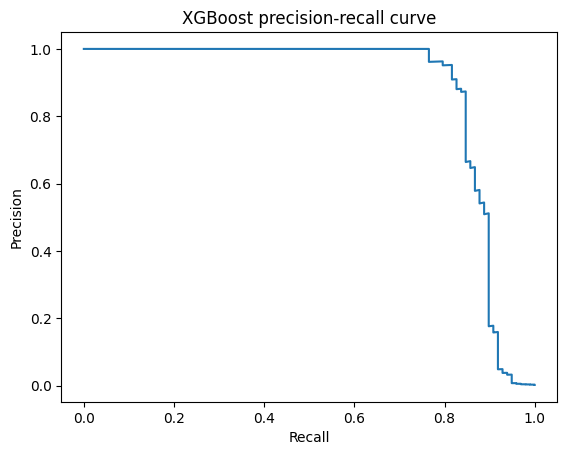

threshold 0.2: precision=0.822 recall=0.847 alerts=101
threshold 0.5: precision=0.874 recall=0.847 alerts=95
threshold 0.8: precision=0.882 recall=0.837 alerts=93
threshold 0.95: precision=0.930 recall=0.816 alerts=86


In [10]:
from sklearn.metrics import precision_recall_curve

proba = xgb.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)
plt.plot(rec, prec)
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("XGBoost precision-recall curve")
plt.show()

for t in [0.2, 0.5, 0.8, 0.95]:
    pred = (proba >= t).astype(int)
    print(f"threshold {t}: precision={precision_score(y_test, pred):.3f} "
          f"recall={recall_score(y_test, pred):.3f} alerts={pred.sum()}")

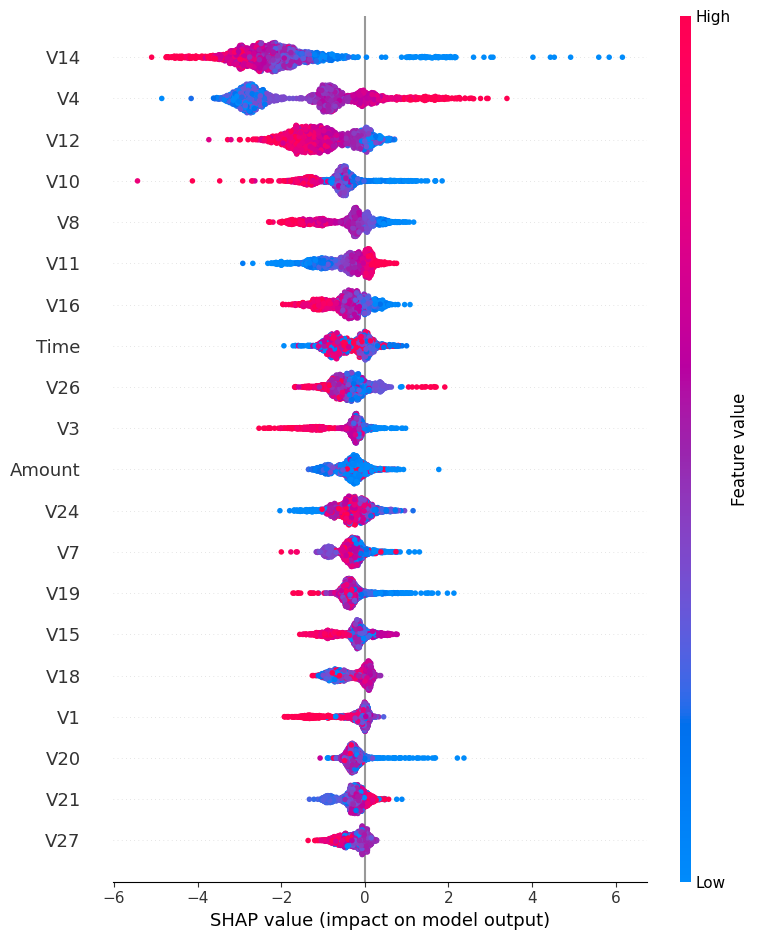

In [12]:
import xgboost as xgb_lib
import shap

sample = X_test.sample(2000, random_state=42)
dmat = xgb_lib.DMatrix(sample)

contribs = xgb.get_booster().predict(dmat, pred_contribs=True)
shap_values = contribs[:, :-1]   # the last column is the bias term, so drop it

shap.summary_plot(shap_values, sample)

In [13]:
def risk_band(p, low=0.2, high=0.8):
    if p >= high: return "HIGH - block / hold"
    if p >= low:  return "MEDIUM - verify with OTP"
    return "LOW - approve"

proba_all = xgb.predict_proba(X_test)[:, 1]
bands = pd.Series([risk_band(p) for p in proba_all])

print(bands.value_counts())
print(pd.crosstab(bands.values, y_test.values,
                  rownames=["band"], colnames=["actual (0=genuine, 1=fraud)"]))

LOW - approve               56861
HIGH - block / hold            93
MEDIUM - verify with OTP        8
Name: count, dtype: int64
actual (0=genuine, 1=fraud)      0   1
band                                  
HIGH - block / hold             11  82
LOW - approve                56846  15
MEDIUM - verify with OTP         7   1


In [14]:
rows = []
yt = y_test.values
for low in [0.01, 0.02, 0.05, 0.1, 0.2]:
    for high in [0.8, 0.95]:
        med = (proba_all >= low) & (proba_all < high)
        hi = proba_all >= high
        rows.append({
            "low": low, "high": high,
            "genuine OTP prompts": int((med & (yt == 0)).sum()),
            "genuine blocked": int((hi & (yt == 0)).sum()),
            "fraud caught": int(((med | hi) & (yt == 1)).sum()),
            "fraud missed": int((~(med | hi) & (yt == 1)).sum()),
        })
pd.DataFrame(rows)

,low,high,genuine OTP prompts,genuine blocked,fraud caught,fraud missed
0,0.01,0.80,145,11,88,10
1,0.01,0.95,150,6,88,10
2,0.02,0.80,84,11,88,10
3,0.02,0.95,89,6,88,10
4,0.05,0.80,37,11,85,13
5,0.05,0.95,42,6,85,13
6,0.10,0.80,15,11,83,15
7,0.10,0.95,20,6,83,15
8,0.20,0.80,7,11,83,15
9,0.20,0.95,12,6,83,15


In [15]:
import json

config = {"low": 0.02, "high": 0.95, "model_file": "xgb_transaction.joblib",
          "scaler_file": "scaler.joblib"}
with open("../models/thresholds.json", "w") as f:
    json.dump(config, f, indent=2)
print("Saved", config)

Saved {'low': 0.02, 'high': 0.95, 'model_file': 'xgb_transaction.joblib', 'scaler_file': 'scaler.joblib'}
